# How well do CLIP features predict macaque IT responses, and how much of that comes from training?

| | |
| --- | --- |
| **Question** | How well does a linear map from CLIP ViT-B/32 features predict held-out responses of 168 macaque IT recording sites, compared with the same network with random weights? |
| **Requires** | The MajajHong2015 public data (downloaded by Brain-Score on first use) and the CLIP ViT-B/32 weights from Hugging Face. A GPU makes feature extraction take seconds; on a CPU it takes several minutes. The linear fits and the benchmark take about 40 minutes. |
| **Lessons used** | [2. Your first benchmark](../lessons/02_your_first_benchmark.ipynb), [3. Wrap a PyTorch model](../lessons/03_wrap_a_pytorch_model.ipynb), [5. Layers and regions](../lessons/05_layers_and_regions.ipynb) |

## Background

Neural predictivity is the standard Brain-Score test of whether a model's internal representation resembles a brain region. Features from one model layer are mapped linearly to recorded responses on training images, and the map is tested on held-out images. The data are multi-unit responses from macaque inferior temporal cortex (IT) to 3,200 images of objects on varied backgrounds (Majaj, Hong et al., 2015, *J. Neurosci.*, [doi:10.1523/JNEUROSCI.5181-14.2015](https://doi.org/10.1523/JNEUROSCI.5181-14.2015); public half).

A linear map from tens of thousands of features can fit a lot, so a high correlation alone does not show that the features are brain-like. The control is the same architecture with random weights: whatever it predicts comes from the architecture and the images, not from training.

## Hypothesis

Trained CLIP features predict held-out IT responses better than random-weight features at most recording sites.

## Method

Partial least squares (PLS) regression with 25 components, as in the benchmark, is fitted on 90% of the images and tested on the other 10%, over 10 splits stratified by object. Each site's score is the Pearson correlation between its predicted and measured held-out responses: 0 means no linear relationship, 1 a perfect one. The values are raw correlations, not divided by the data's noise ceiling.

## Setup

Imports and settings.

In [1]:
# Keep the output short: no progress bars, no library warnings.
import warnings
from functools import partialmethod
from tqdm.auto import tqdm
import tqdm as _tqdm
for _bar in (tqdm, _tqdm.tqdm):
    _bar.__init__ = partialmethod(_bar.__init__, disable=True)
warnings.filterwarnings('ignore')
import os
os.environ['BS_INSTALL_DEPENDENCIES'] = 'no'      # every requirement is already installed

import numpy as np
import matplotlib.pyplot as plt
import brainscore

## The subjects

Both are registered models: CLIP ViT-B/32 as trained, and the same architecture with random weights. Each one's region map assigns `IT` to `encoder.layers.10`.

In [2]:
subjects = {name: brainscore.load_model(name) for name in ('clip-vit-b-32', 'random-vit-b-32')}

[transformers] The `use_fast` parameter is deprecated and will be removed in a future version. Use `backend="torchvision"` instead of `use_fast=True`, or `backend="pil"` instead of `use_fast=False`.


## The experiment

### Stimuli and recordings

The registered benchmark's own loader gives the IT sites only, with responses averaged over repetitions: one value per image and site. Its stimulus set holds the 3,200 images.

In [3]:
from brainscore_vision.benchmarks.majajhong2015.benchmark import load_assembly

it = load_assembly(average_repetitions=True, region='IT', access='public')
print(it.dims, it.shape)                            # (images, IT sites)

('presentation', 'neuroid') (3200, 168)


### Task

Plain viewing: each image is shown once and the subject's `IT` layer is recorded. There is no answer to give.

## Run

`neural_response` builds a viewing session for the stimulus set, runs the subject through it, and returns the recording.

In [4]:
from brainscore_core.streaming_helpers import neural_response

features = {name: neural_response(subject, it.stimulus_set, ['neural:IT'])
            for name, subject in subjects.items()}

Activation cache bypassed: unsupported torch.dtype; define cache_config()


## Read results back

Each recording has one row per image and one column per unit (38,400 for this layer). The rows follow the stimulus set's order, so they are put in the order of the neural data, matched by stimulus ID, before any comparison.

In [5]:
Y = np.asarray(it.values)                           # measured responses: (images, sites)
row_of = {stimulus: i for i, stimulus in enumerate(it['stimulus_id'].values)}

X = {}                                              # model features, rows in Y's order
for name, assembly in features.items():
    rows = [row_of[stimulus] for stimulus in assembly['stimulus_id'].values]
    X[name] = np.empty((len(Y), assembly.shape[1]))
    X[name][rows] = np.asarray(assembly.values)
    print(name, X[name].shape)

clip-vit-b-32 (3200, 38400)


random-vit-b-32 (3200, 38400)


## Analysis

In [6]:
from scipy.stats import pearsonr
from sklearn.cross_decomposition import PLSRegression
from sklearn.model_selection import StratifiedShuffleSplit

# The same 10 splits for both networks, stratified by object so every object is in every training set.
objects = np.asarray(it['object_name'].values)
SPLITS = list(StratifiedShuffleSplit(n_splits=10, train_size=0.9, random_state=0).split(Y, objects))

def held_out_predictions(X, Y):
    """Each image's predicted response, averaged over the splits in which it was held out."""
    total, count = np.zeros_like(Y, dtype=float), np.zeros(len(Y))
    for train, test in SPLITS:
        pls = PLSRegression(n_components=25, scale=False).fit(X[train], Y[train])
        total[test] += pls.predict(X[test])
        count[test] += 1
    seen = count > 0                                # images held out at least once
    return total[seen] / count[seen, None], seen

def site_correlations(prediction, measured):
    """Pearson r between predicted and measured responses, one value per site."""
    return np.array([pearsonr(prediction[:, j], measured[:, j])[0] for j in range(measured.shape[1])])

## Results

In [7]:
prediction, site_r = {}, {}
for name in X:
    prediction[name], seen = held_out_predictions(X[name], Y)
    site_r[name] = site_correlations(prediction[name], Y[seen])
    print(f'{name:16s} median r across sites = {np.median(site_r[name]):.3f}')

trained, random = site_r['clip-vit-b-32'], site_r['random-vit-b-32']
print(f'trained better at {np.mean(trained > random):.0%} of {len(trained)} sites; '
      f'median gain {np.median(trained - random):+.3f}')

clip-vit-b-32    median r across sites = 0.559


random-vit-b-32  median r across sites = 0.298
trained better at 99% of 168 sites; median gain +0.262


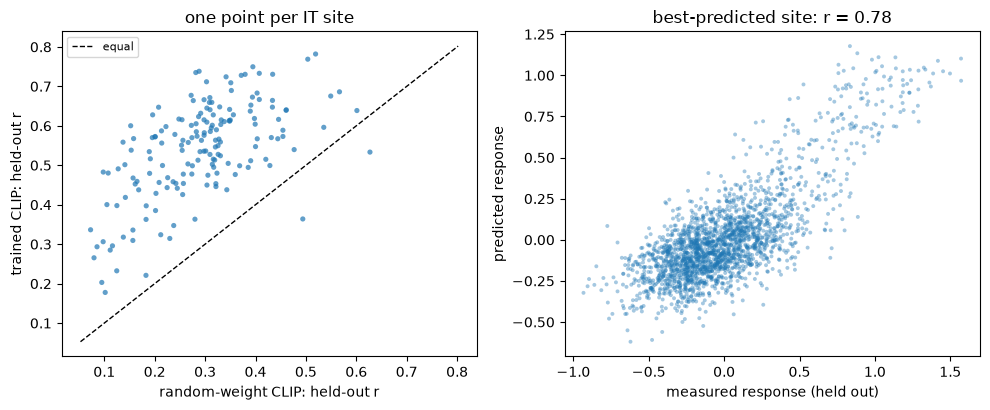

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))

ax = axes[0]                                        # one point per site: above the line = training helps
ax.scatter(random, trained, s=14, alpha=0.7, edgecolor='none')
lo, hi = min(random.min(), trained.min()) - 0.02, max(random.max(), trained.max()) + 0.02
ax.plot([lo, hi], [lo, hi], 'k--', lw=1, label='equal')
ax.set_xlabel('random-weight CLIP: held-out r'); ax.set_ylabel('trained CLIP: held-out r')
ax.set_title('one point per IT site'); ax.legend(fontsize=8)

best = int(np.argmax(trained))                      # the most favorable site, not a typical one
ax = axes[1]
ax.scatter(Y[seen, best], prediction['clip-vit-b-32'][:, best], s=8, alpha=0.4, edgecolor='none')
ax.set_xlabel('measured response (held out)'); ax.set_ylabel('predicted response')
ax.set_title(f'best-predicted site: r = {trained[best]:.2f}')
fig.tight_layout(); plt.show()

The left panel answers the question site by site. The right panel shows held-out predictions for the best site; its correlation is an upper bound, not a typical value.

### The same measurement as a registered benchmark

The registered benchmark runs the same procedure with its own splits and divides by the noise ceiling, so its score is on the leaderboard's scale.

In [9]:
for name in subjects:
    score = brainscore.score(name, 'MajajHong2015public.IT-pls-unified')
    print(f'{name:16s} benchmark score {float(score):.3f}')

Activation cache bypassed: unsupported torch.dtype; define cache_config()


Activation cache bypassed: unsupported torch.dtype; define cache_config()


clip-vit-b-32    benchmark score 0.374


random-vit-b-32  benchmark score 0.111


## Conclusion and limits

The result supports the hypothesis. Trained CLIP features predicted held-out IT responses with a median correlation of 0.559 across the 168 sites, against 0.298 for the same network with random weights; trained features were better at 99% of sites, by a median of 0.26. Random features already predict a good part of IT's response, so the training effect is the gap, not the trained value alone. On the benchmark's own scale, divided by the noise ceiling, the scores are 0.374 and 0.111.

Limits: one layer per network, chosen by the region map rather than fitted to these data; one random initialization; the public half of the data. The comparison does not say which aspect of CLIP's training matters; comparing with other trained networks on the same benchmark would.

[Lessons](../lessons/) · [Documentation](../../docs/README.md)